# Exploring Skill Demand

## Methodology

1. Clean up data.
2. Calculate skill count for each job title.
3. Calculate skill percentage.
4. Plot the findings.

In [2]:
#Import libraries
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

#Load dataset
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

#Data cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

#Focus on UK jobs
df_uk = df[df['job_country'] == 'United Kingdom'].copy()

## Prepare Counts Data

In [3]:
#Explode the skills list
df_uk_explode = df_uk.explode('job_skills')

In [4]:
#Find the number of jobs which list each skill
df_skills_count = df_uk_explode.groupby(['job_skills', 'job_title_short']).size()
df_skills_count = df_skills_count.reset_index(name='skill_count') #revert it from a series to a df
df_skills_count.sort_values(by='skill_count', ascending=False, inplace=True) #sort by skill count
df_skills_count

,job_skills,job_title_short,skill_count
1163,sql,Data Engineer,7050
915,python,Data Engineer,6462
916,python,Data Scientist,6329
88,azure,Data Engineer,4865
1162,sql,Data Analyst,4467
...,...,...,...
1368,vue.js,Software Engineer,1
1367,vue.js,Senior Data Engineer,1
514,javascript,Machine Learning Engineer,1
551,julia,Software Engineer,1


In [5]:
#Create a list of the three most common job titles in alphabetical order
job_titles = sorted(df_skills_count['job_title_short'].unique().tolist()[:3])
job_titles


['Data Analyst', 'Data Engineer', 'Data Scientist']

## Plot Counts Data

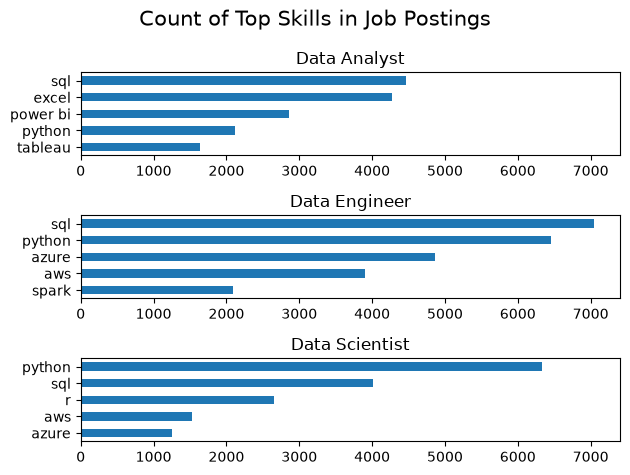

In [6]:
fig, ax = plt.subplots(len(job_titles),1)

for i, job_title in enumerate(job_titles):
    
    df_plot = df_skills_count[df_skills_count['job_title_short'] == job_title].head(5)
    df_plot[::-1].plot(kind='barh', x='job_skills', y='skill_count', ax=ax[i], title=job_title)
    
    ax[i].set_ylabel('')
    ax[i].legend().set_visible(False)
    ax[i].set_xlim(0,max(df_skills_count['skill_count'])*1.05)
    
fig.suptitle('Count of Top Skills in Job Postings', fontsize=15)

fig.tight_layout()
plt.show()

## Prepare Percentage Data

In [7]:
#Create a df of the number of uk job listings
df_counts = df_uk['job_title_short'].value_counts().reset_index(name='jobs_total').copy()
df_counts

,job_title_short,jobs_total
0,Data Engineer,11807
1,Data Analyst,10482
2,Data Scientist,9148
3,Senior Data Engineer,3337
4,Senior Data Scientist,2367
5,Senior Data Analyst,1356
6,Business Analyst,827
7,Software Engineer,541
8,Machine Learning Engineer,317
9,Cloud Engineer,193


In [8]:
#merge the top 3 with the df_skills_count df
df_skill_perc = pd.merge(df_skills_count,
                        df_counts,
                        how='left', 
                        on='job_title_short')

df_skill_perc['skill_perc'] = (df_skill_perc['skill_count']/df_skill_perc['jobs_total']*100)
df_skill_perc

,job_skills,job_title_short,skill_count,jobs_total,skill_perc
0,sql,Data Engineer,7050,11807,59.710341
1,python,Data Engineer,6462,11807,54.730245
2,python,Data Scientist,6329,9148,69.184521
3,azure,Data Engineer,4865,11807,41.204370
4,sql,Data Analyst,4467,10482,42.615913
...,...,...,...,...,...
1414,vue.js,Software Engineer,1,541,0.184843
1415,vue.js,Senior Data Engineer,1,3337,0.029967
1416,javascript,Machine Learning Engineer,1,317,0.315457
1417,julia,Software Engineer,1,541,0.184843


## Plot Percentage Data

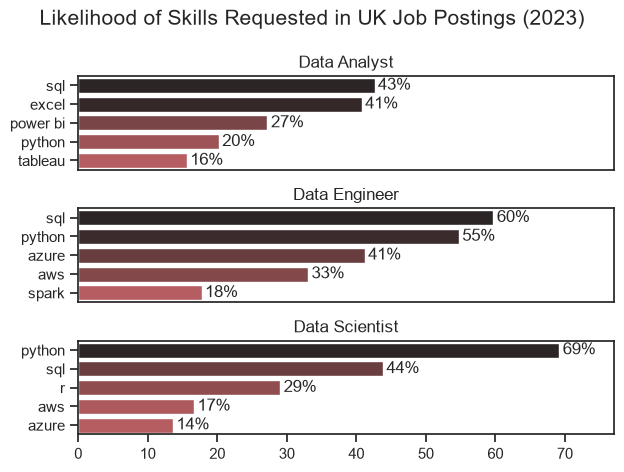

In [12]:
#Set up the plot
fig, ax = plt.subplots(len(job_titles),1)

#For loop to create plot for each job_title item
for i, job_title in enumerate(job_titles):
    
    #Set the theme
    sns.set_theme(style='ticks')
    
    #Subset the data for our top 3 job titles
    df_plot = df_skill_perc[df_skill_perc['job_title_short'] == job_title].head(5)
    
    #Plot using seaborn
    sns.barplot(data=df_plot, x='skill_perc', y='job_skills', ax=ax[i], hue='skill_count', palette='dark:r_r')
    ax[i].set_title(job_title)
    ax[i].set_ylabel('')
    ax[i].set_xlim(0,max(df_skill_perc['skill_perc'])*1.05)
    ax[i].set_xlabel('')
    ax[i].legend().set_visible(False)

    
    for n, v in enumerate(df_plot['skill_perc']):
        ax[i].text(x=v+0.5, y=n, s=f'{v:.0f}%', va='center')
    
    if i != 2:
        ax[i].set_xticks([])
    
#Set the figure title and global options
fig.suptitle('Likelihood of Skills Requested in UK Job Postings (2023)', fontsize=15)
fig.tight_layout()
plt.savefig('Figures/Skills_Demand.png')
plt.show()

